In [1]:
import os
import zarr
import scanpy

import numpy as np
import timm

import torch
from torchvision.transforms import ToTensor, Resize, Compose

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

In [2]:
device = 'cuda'

In [3]:
fov_size = 256

In [ ]:
index_array = zarr.open("../../data/Xenium_Prime_Human_Breast_Cancer_FFPE/indices.zarr", mode="r")
image_array = zarr.open("../../data/Xenium_Prime_Human_Breast_Cancer_FFPE/image.zarr", mode="r")
spatial_anndata = scanpy.read_h5ad("../../data/Xenium_Prime_Human_Breast_Cancer_FFPE/spatial_preprocessed_breast_cancer.h5")

In [4]:
index_array = zarr.open("../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/indices.zarr", mode="r")
image_array = zarr.open("../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/image.zarr", mode="r")
spatial_anndata = scanpy.read_h5ad("../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/spatial_preprocessed_lung_cancer.h5")

In [ ]:
index_array_2 = zarr.open("../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/indices.zarr", mode="r")
image_array_2 = zarr.open("../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/image.zarr", mode="r")
spatial_anndata_2 = scanpy.read_h5ad("../../data/Xenium_Prime_Human_Lung_Cancer_FFPE/spatial_preprocessed_lung_cancer.h5")

In [5]:
# Image encoder
pretrained_ckpt_dir = "../assets/ckpts/vit_large_patch16_224.dinov2.uni_mass100k/"

os.listdir("../assets/ckpts/vit_large_patch16_224.dinov2.uni_mass100k/")

os.makedirs(pretrained_ckpt_dir, exist_ok=True)

image_encoder = timm.create_model(
    "vit_large_patch16_224",
    img_size=224,
    patch_size=16,
    init_values=1e-5,
    num_classes=0,
    dynamic_img_size=True,
)
image_encoder.load_state_dict(
    torch.load(
        os.path.join(pretrained_ckpt_dir, "pytorch_model.bin"), map_location="cpu"
    ),
    strict=True,
)
image_encoder.to(device)
image_encoder.eval()

RuntimeError: No CUDA GPUs are available

In [ ]:
index_array.shape[0]

In [6]:
li_num_cells = []
li_spatial_fov_embeddings = []
li_image_fov_embedding = []

for idx in range(index_array.shape[0]):
    slice_args = index_array[idx, :, :]
    y_start = slice_args[0, :].item()
    x_start = slice_args[1, :].item()
    
    points = spatial_anndata.obsm["spatial"]
    
    mask = (
        (x_start <= points[:, 0])
        & (points[:, 0] < x_start + fov_size)
        & (y_start <= points[:, 1])
        & (points[:, 1] < y_start + fov_size)
    )
    
    spatial_embedding = (
        torch.Tensor(spatial_anndata.obsm["novae_latent"][mask])
        # .mean(dim=0)
    )
    
    # try:
    #     torch.Tensor(spatial_anndata.obsm["novae_latent"][mask]).mean(dim=0) == 0
    # except:
    #     import pdb;pdb.set_trace()
        
    num_cells_in_FOV = len(spatial_anndata.obsm["novae_latent"][mask])
    
    
    # fov_image = image_array[
    #         y_start : y_start + fov_size, 
    #         x_start : x_start + fov_size, 
    #         :
    #         ]
    # transform = Compose([ToTensor(), Resize((224, 224))])
    # fov_image = transform(fov_image)
    # with torch.no_grad():
    #     image_embedding = image_encoder(fov_image.unsqueeze(0).to(device))
    
    li_num_cells.append(num_cells_in_FOV)
    li_spatial_fov_embeddings.append(spatial_embedding)
    # li_image_fov_embedding.append(image_embedding)
    # import pdb;pdb.set_trace()

In [ ]:
li_num_cells = []
li_spatial_fov_embeddings = []
li_image_fov_embedding = []

for idx in range(index_array.shape[0]):
    slice_args = index_array[idx, :, :]
    y_start = slice_args[0, :].item()
    x_start = slice_args[1, :].item()
    
    points = spatial_anndata.obsm["spatial"]
    
    mask = (
        (x_start <= points[:, 0])
        & (points[:, 0] < x_start + fov_size)
        & (y_start <= points[:, 1])
        & (points[:, 1] < y_start + fov_size)
    )
    
    spatial_embedding = (
        torch.Tensor(spatial_anndata.obsm["novae_latent"][mask])
        # .mean(dim=0)
    )
    
    # try:
    #     torch.Tensor(spatial_anndata.obsm["novae_latent"][mask]).mean(dim=0) == 0
    # except:
    #     import pdb;pdb.set_trace()
        
    num_cells_in_FOV = len(spatial_anndata.obsm["novae_latent"][mask])
    
    
    # fov_image = image_array[
    #         y_start : y_start + fov_size, 
    #         x_start : x_start + fov_size, 
    #         :
    #         ]
    # transform = Compose([ToTensor(), Resize((224, 224))])
    # fov_image = transform(fov_image)
    # with torch.no_grad():
    #     image_embedding = image_encoder(fov_image.unsqueeze(0).to(device))
    
    li_num_cells.append(num_cells_in_FOV)
    li_spatial_fov_embeddings.append(spatial_embedding)
    # li_image_fov_embedding.append(image_embedding)
    # import pdb;pdb.set_trace()
    
    
for idx in range(index_array_2.shape[0]):
    slice_args = index_array_2[idx, :, :]
    y_start = slice_args[0, :].item()
    x_start = slice_args[1, :].item()
    
    points = spatial_anndata_2.obsm["spatial"]
    
    mask = (
        (x_start <= points[:, 0])
        & (points[:, 0] < x_start + fov_size)
        & (y_start <= points[:, 1])
        & (points[:, 1] < y_start + fov_size)
    )
    
    spatial_embedding = (
        torch.Tensor(spatial_anndata_2.obsm["novae_latent"][mask])
        # .mean(dim=0)
    )
    
    # try:
    #     torch.Tensor(spatial_anndata.obsm["novae_latent"][mask]).mean(dim=0) == 0
    # except:
    #     import pdb;pdb.set_trace()
        
    num_cells_in_FOV = len(spatial_anndata_2.obsm["novae_latent"][mask])
    

    # fov_image = image_array_2[
    #         y_start : y_start + fov_size, 
    #         x_start : x_start + fov_size, 
    #         :
    #         ]
    # transform = Compose([ToTensor(), Resize((224, 224))])
    # fov_image = transform(fov_image)
    # with torch.no_grad():
    #     image_embedding = image_encoder(fov_image.unsqueeze(0).to(device))
    
    li_num_cells.append(num_cells_in_FOV)
    li_spatial_fov_embeddings.append(spatial_embedding)
    # li_image_fov_embedding.append(image_embedding)
    # import pdb;pdb.set_trace()

# Embedding collapse already in novae embedding

In [ ]:
plt.hist(spatial_anndata.obsm["novae_latent"].mean(axis=1), bins=100)
plt.xlabel("Mean of spatial embeddings")
plt.ylabel("Cell counts")
plt.title("Histogram")
plt.show()

In [ ]:
plt.hist(np.array(li_image_fov_embedding).squeeze(1).mean(axis=1))
plt.show()

In [ ]:
for item in li_spatial_fov_embeddings:
    if item.shape[0] != 1 and len(item) !=0:
        import pdb;pdb.set_trace()

In [ ]:
plt.hist(np.array(li_image_fov_embedding).squeeze(1).mean(axis=1))
plt.show()

In [9]:
counts.max()

10907

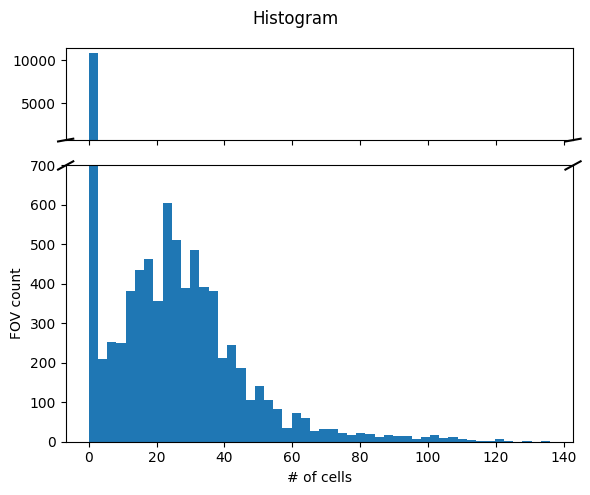

In [13]:
# 히스토그램 데이터 먼저 계산 (공통으로 써야 해서)
counts, bin_edges = np.histogram(li_num_cells, bins=50)

# 공통 x 위치 (bin 중심)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# 서브플롯 만들기
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6, 5), 
                               gridspec_kw={'height_ratios': [1, 3]})

# 윗축: 높은 y값 (17500 이상)
ax1.bar(bin_centers, counts, width=np.diff(bin_edges), align='center')
ax1.set_ylim(700, max(counts) * 1.05)  # 윗부분만 보여줌

# 아래축: 낮은 y값 (0~5000)
ax2.bar(bin_centers, counts, width=np.diff(bin_edges), align='center')
ax2.set_ylim(0, 700)

# 깨진 축 표시 삽입
d = .015
kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
ax1.plot((-d, +d), (-d, +d), **kwargs)        # 좌상단
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)  # 우상단

kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # 좌하단
ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)  # 우하단

# 라벨 및 제목
ax2.set_xlabel("# of cells")
ax2.set_ylabel("FOV count")
fig.suptitle("Histogram")

plt.tight_layout()
plt.show()


In [ ]:
torch.Tensor(li_spatial_fov_embeddings)

In [ ]:
spatial_anndata.obsm["novae_latent"]

In [ ]:
data = spatial_anndata.obsm["novae_latent"]
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
z_tsne = tsne.fit_transform(data)

plt.figure(figsize=(6, 6))
plt.scatter(z_tsne[:, 0], z_tsne[:, 1], label='Image', alpha=0.7)
plt.legend()
plt.title("t-SNE of Spatial Embeddings")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.grid(True)
plt.tight_layout()
plt.show()